In [10]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import time
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

In [11]:
(x_train,y_train),(x_test,y_test)=tf.keras.datasets.mnist.load_data()

x_train=x_train[:10000].reshape(-1,784)/255.0
x_test=x_test[:2000].reshape(-1,784)/255.0
y_train=y_train[:10000]
y_test=y_test[:2000]

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step


In [12]:
model=tf.keras.Sequential([
    tf.keras.layers.Input(shape=(784,)),
    tf.keras.layers.Dense(128,activation='relu'),
    tf.keras.layers.Dense(128,activation='relu'),
    tf.keras.layers.Dense(128,activation='relu'),
    tf.keras.layers.Dense(10,activation='softmax')
])

model.compile(optimizer=tf.keras.optimizers.Adam(0.001),
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

In [13]:
start=time.time()
history=model.fit(x_train,y_train,epochs=3,batch_size=128)
mlp_time=time.time()-start

loss,acc=model.evaluate(x_test,y_test)
print("MLP Accuracy:",acc*100)
print("Training Time:",mlp_time)

Epoch 1/3
79/79 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.7966 - loss: 0.7370
Epoch 2/3
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.9214 - loss: 0.2679
Epoch 3/3
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.9426 - loss: 0.1938
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9145 - loss: 0.3034
MLP Accuracy: 91.44999980926514
Training Time: 5.602843761444092


In [14]:
start=time.time()
lr=LogisticRegression(max_iter=100)
lr.fit(x_train,y_train)
lr_time=time.time()-start

lr_acc=accuracy_score(y_test,lr.predict(x_test))
print("Logistic Regression Accuracy:",lr_acc*100)
print("Training Time:",lr_time)

Logistic Regression Accuracy: 87.05000000000001
Training Time: 2.3405420780181885


C:\Users\Lenovo\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [15]:
start=time.time()
dt=DecisionTreeClassifier()
dt.fit(x_train,y_train)
dt_time=time.time()-start

dt_acc=accuracy_score(y_test,dt.predict(x_test))
print("Decision Tree Accuracy:",dt_acc*100)
print("Training Time:",dt_time)

Decision Tree Accuracy: 77.14999999999999
Training Time: 5.390296697616577


In [16]:
print("MLP:",acc*100)
print("Logistic Regression:",lr_acc*100)
print("Decision Tree:",dt_acc*100)

MLP: 91.44999980926514
Logistic Regression: 87.05000000000001
Decision Tree: 77.14999999999999


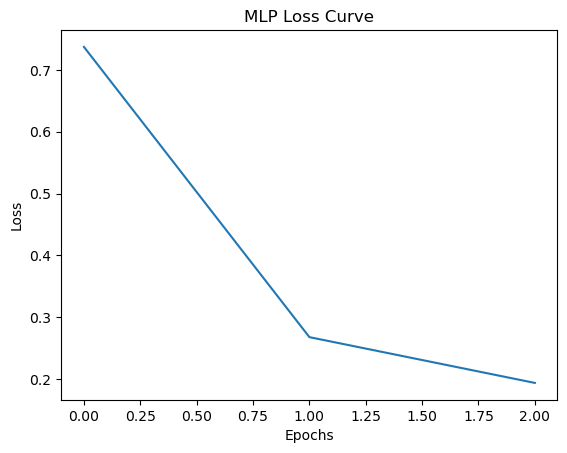

In [17]:
plt.plot(history.history['loss'])
plt.title("MLP Loss Curve")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.show()

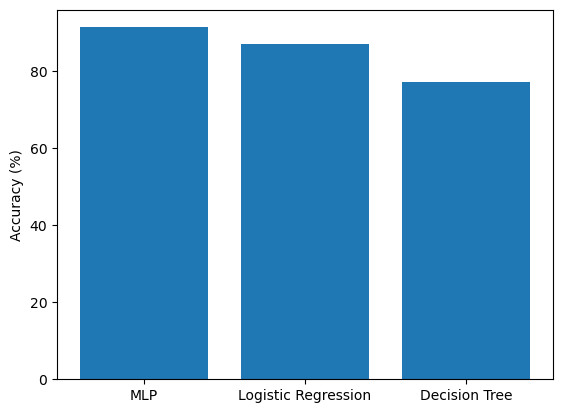

In [18]:
plt.bar(['MLP','Logistic Regression','Decision Tree'],
        [acc*100,lr_acc*100,dt_acc*100])
plt.ylabel("Accuracy (%)")
plt.show()